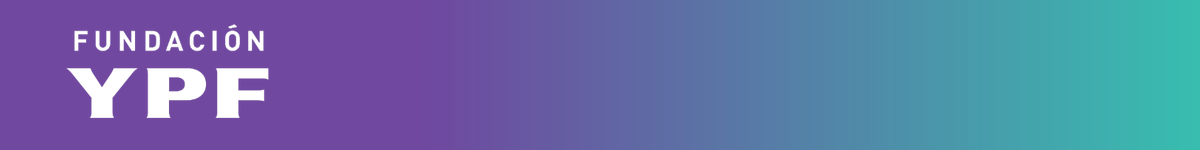

# Fundación YPF - Data Science

## Notebook 30: Perceptrón simple y multicapa

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: perceptrón simple con datos separables
* **Parte 2:** El problema de los datos no separables linealmente
* **Parte 3:** Perceptrón multicapa (MLPClassifier)
* **Parte 4:** Aplicación a un dataset real: recurrencia de cáncer de mama
* **Parte 5:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

En la clase anterior vimos el **perceptrón simple**: una neurona que combina los features con pesos, pasa el resultado por una función **sigmoidea** y devuelve una probabilidad entre 0 y 1. También vimos cómo se entrena: el **descenso por gradiente** busca los pesos que minimizan una función de costo.

Hoy cerramos esa cadena con la **entropía cruzada** (la función de costo que se usa para clasificación), el **forward propagation** y el **backpropagation** (cómo se calcula el costo y cómo se actualizan los pesos), y vemos por qué una sola neurona no alcanza para todos los problemas: el **perceptrón multicapa**.

**Datasets:**

* Datos sintéticos generados con `scikit-learn` (`make_classification`, `make_circles`, `make_moons`): no hace falta subir ningún archivo para esa parte.
* `cancer_mamario.csv`: datos de pacientes con cáncer de mama, para ver si hubo recurrencia. Lo usamos para aplicar lo visto a un problema real.

Antes de ejecutar, subí el archivo `cancer_mamario.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification, make_circles, make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso: perceptrón simple con datos separables

El perceptrón simple es, en esencia, una **regresión logística**: una neurona con función de activación sigmoidea. Funciona bien cuando las clases se pueden separar con una línea (en 2D) o un hiperplano (en más dimensiones). Generamos datos sintéticos linealmente separables y lo comprobamos.

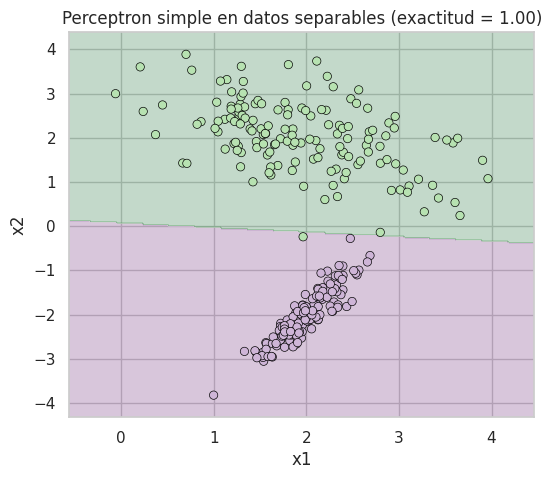

Exactitud del perceptron simple: 0.997


In [2]:
def graficar_frontera(modelo, X, y, titulo, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="PRGn")
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette="PRGn", ax=ax, edgecolor="black", legend=False)
    ax.set_title(titulo)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    return ax


X_sep, y_sep = make_classification(
    n_samples=300, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=2.0, random_state=RANDOM_STATE,
)

perceptron_simple = LogisticRegression(random_state=RANDOM_STATE)
perceptron_simple.fit(X_sep, y_sep)
acc_sep = accuracy_score(y_sep, perceptron_simple.predict(X_sep))

graficar_frontera(perceptron_simple, X_sep, y_sep, f"Perceptron simple en datos separables (exactitud = {acc_sep:.2f})")
plt.show()

print(f"Exactitud del perceptron simple: {acc_sep:.3f}")

Con datos separables, el perceptrón simple encuentra una frontera lineal que clasifica casi perfectamente. El problema aparece cuando las clases no se pueden separar con una línea, como vemos a continuación.

## Parte 2: El problema de los datos no separables linealmente

Generamos datos con forma de círculos concéntricos (`make_circles`): una clase forma un anillo exterior y la otra, un círculo interior. No existe ninguna línea recta que las separe bien. Probamos el mismo perceptrón simple sobre estos datos.

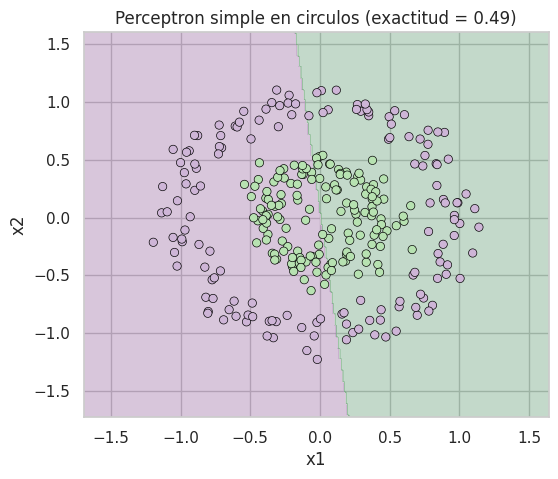

Exactitud del perceptron simple: 0.493


In [3]:
X_circ, y_circ = make_circles(n_samples=300, noise=0.1, factor=0.4, random_state=RANDOM_STATE)

perceptron_simple_circ = LogisticRegression(random_state=RANDOM_STATE)
perceptron_simple_circ.fit(X_circ, y_circ)
acc_circ_simple = accuracy_score(y_circ, perceptron_simple_circ.predict(X_circ))

graficar_frontera(perceptron_simple_circ, X_circ, y_circ, f"Perceptron simple en circulos (exactitud = {acc_circ_simple:.2f})")
plt.show()

print(f"Exactitud del perceptron simple: {acc_circ_simple:.3f}")

La frontera que encuentra el modelo sigue siendo una línea recta: es lo único que puede dibujar una sola neurona con activación sigmoidea. Como la clase positiva está en un anillo alrededor de la negativa, ninguna línea las separa bien y la exactitud queda muy por debajo de lo que vimos en la Parte 1. Necesitamos un modelo que pueda dibujar fronteras curvas: el perceptrón multicapa.

## Parte 3: Perceptrón multicapa (MLPClassifier)

El perceptrón multicapa agrega una o más **capas ocultas** de neuronas entre la entrada y la salida. Cada neurona de la capa oculta aplica su propia combinación lineal y su propia función de activación (por defecto, scikit-learn usa **ReLU**). Esto le permite combinar varias fronteras lineales y armar una frontera curva. Entrenamos un `MLPClassifier` sobre los mismos círculos.

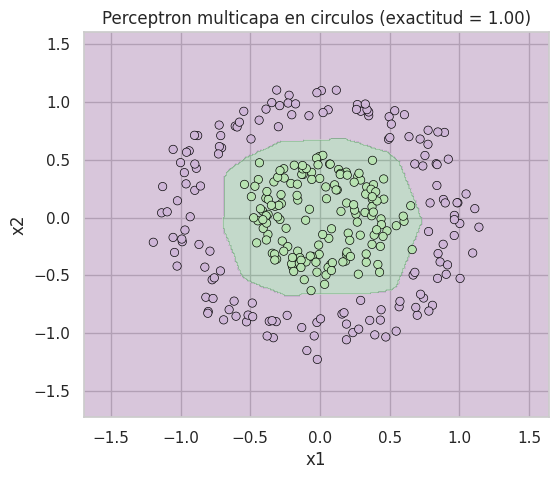

Exactitud del perceptron multicapa: 0.997


In [4]:
mlp_circ = MLPClassifier(
    hidden_layer_sizes=(16, 16), activation="relu", solver="adam",
    max_iter=2000, random_state=RANDOM_STATE,
)
mlp_circ.fit(X_circ, y_circ)
acc_circ_mlp = accuracy_score(y_circ, mlp_circ.predict(X_circ))

graficar_frontera(mlp_circ, X_circ, y_circ, f"Perceptron multicapa en circulos (exactitud = {acc_circ_mlp:.2f})")
plt.show()

print(f"Exactitud del perceptron multicapa: {acc_circ_mlp:.3f}")

El perceptrón multicapa encuentra una frontera curva y separa las dos clases con una exactitud mucho más alta que el perceptrón simple. Por dentro, scikit-learn hace exactamente lo que vimos en la teoría: en cada iteración calcula las predicciones y el costo con entropía cruzada (forward propagation), deriva ese costo hacia atrás hasta cada peso (backpropagation) y actualiza los pesos con descenso por gradiente. Podemos ver ese descenso mirando la curva de pérdida durante el entrenamiento.

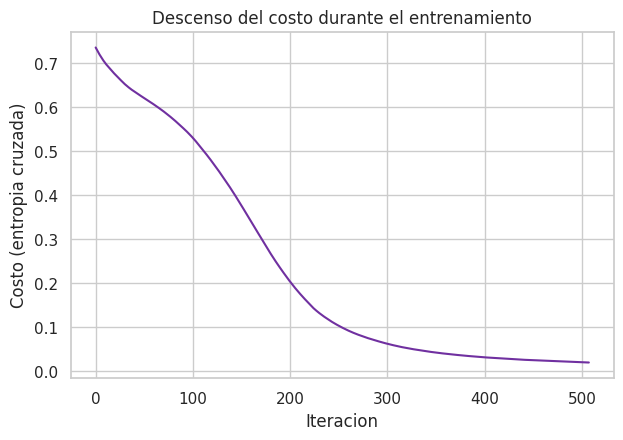

Costo final: 0.0197
Cantidad de iteraciones hasta converger: 508


In [5]:
plt.figure(figsize=(7, 4.5))
plt.plot(mlp_circ.loss_curve_, color="#7030A0")
plt.xlabel("Iteracion")
plt.ylabel("Costo (entropia cruzada)")
plt.title("Descenso del costo durante el entrenamiento")
plt.show()

print(f"Costo final: {mlp_circ.loss_curve_[-1]:.4f}")
print(f"Cantidad de iteraciones hasta converger: {mlp_circ.n_iter_}")

La curva baja rápido al principio y después se aplana: así se ve el descenso por gradiente convergiendo hacia un mínimo de la función de costo, iteración a iteración de forward y backward propagation.

## Parte 4: Aplicación a un dataset real: recurrencia de cáncer de mama

Hasta acá usamos datos sintéticos para ver por qué hace falta más de una capa. Ahora aplicamos perceptrón simple y perceptrón multicapa a un problema real: predecir si hubo recurrencia del cáncer a partir de datos clínicos de la paciente (edad, tamaño del tumor, grado de malignidad, si recibió radioterapia, etc.).

In [6]:
if not os.path.exists("cancer_mamario.csv"):
    from google.colab import files
    files.upload()

cancer = pd.read_csv("cancer_mamario.csv")

# Los valores faltantes vienen marcados con "?"
cancer = cancer.replace("?", np.nan)
for col in cancer.columns:
    if cancer[col].isnull().sum() > 0:
        cancer[col] = cancer[col].fillna(cancer[col].mode()[0])

y_cancer = (cancer["class"] == "recurrence-events").astype(int)
X_cancer = pd.get_dummies(cancer.drop(columns=["class"]), drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_cancer, y_cancer, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cancer,
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Observaciones de entrenamiento:", X_train_s.shape[0])
print("Observaciones de prueba:", X_test_s.shape[0])
print("Features luego del encoding:", X_train_s.shape[1])

Observaciones de entrenamiento: 228
Observaciones de prueba: 58
Features luego del encoding: 31


Entrenamos los dos modelos sobre el conjunto de entrenamiento y medimos la exactitud sobre el conjunto de prueba, que el modelo no vio durante el entrenamiento.

In [7]:
perceptron_simple_cancer = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
perceptron_simple_cancer.fit(X_train_s, y_train)
acc_simple_cancer = accuracy_score(y_test, perceptron_simple_cancer.predict(X_test_s))

mlp_cancer = MLPClassifier(
    hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
    max_iter=2000, random_state=RANDOM_STATE,
)
mlp_cancer.fit(X_train_s, y_train)
acc_mlp_cancer = accuracy_score(y_test, mlp_cancer.predict(X_test_s))

comparacion = pd.DataFrame({
    "modelo": ["Perceptron simple (regresion logistica)", "Perceptron multicapa (MLP)"],
    "exactitud_test": [acc_simple_cancer, acc_mlp_cancer],
})
comparacion

,modelo,exactitud_test
0,Perceptron simple (regresion logistica),0.706897
1,Perceptron multicapa (MLP),0.672414


En este dataset real, chico (apenas 228 observaciones de entrenamiento) y con muchas variables categóricas, el perceptrón simple queda levemente por encima del perceptrón multicapa. No es un error: con pocos datos y un modelo con muchos más parámetros para ajustar, el perceptrón multicapa tiene más riesgo de sobreajustar, es decir, de aprender particularidades del conjunto de entrenamiento que no generalizan al conjunto de prueba. Esto muestra algo importante: el perceptrón multicapa no es automáticamente mejor. Aporta más cuando hay suficientes datos y la relación entre las variables y la clase es fuertemente no lineal, como en los círculos de la Parte 2 y 3. Con pocos datos, conviene probar ambos modelos y, si se usa el multicapa, controlar el sobreajuste (algo que vamos a ver en la próxima clase con regularización y dropout).

## Parte 5: Ejercicio para las salas de Zoom

**Dataset:** datos sintéticos con forma de medialunas (`make_moons`), generados con `scikit-learn`. No hace falta subir ningún archivo.

**Contexto:** ya vimos que el perceptrón simple separa bien datos lineales pero falla en los círculos, y que el perceptrón multicapa resuelve ese problema. Ahora repitan el análisis con otra forma de datos no separables linealmente.

**Objetivo:** comparar un perceptrón simple y un perceptrón multicapa sobre `make_moons` y explicar la diferencia.

**Tiempo:** 30 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Generar los datos.** Usen `make_moons(n_samples=300, noise=0.2, random_state=42)`.
2. **Perceptrón simple.** Entrenen una `LogisticRegression`, calculen la exactitud y grafiquen la frontera con `graficar_frontera`.
3. **Perceptrón multicapa.** Entrenen un `MLPClassifier` (prueben con distinto número de neuronas en la capa oculta), calculen la exactitud y grafiquen la frontera.
4. **Curva de costo.** Grafiquen `loss_curve_` del MLP entrenado.
5. **Conclusión.** ¿Cuál modelo funciona mejor con estos datos? ¿Por qué el perceptrón simple no puede resolverlo?

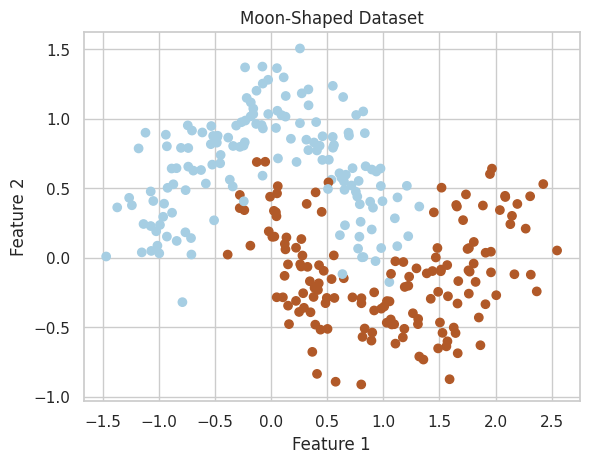

In [14]:
# 1. Generar los datos
# Usen make_moons(n_samples=300, noise=0.2, random_state=42)

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

# Visualize the dataset
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired)
plt.title("Moon-Shaped Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

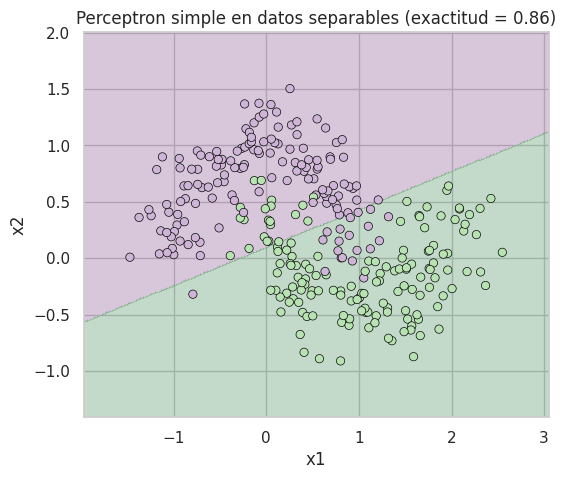

Exactitud del perceptron simple: 0.863


In [15]:
# 2. Perceptron simple
# Perceptrón simple. Entrenen una LogisticRegression, calculen la exactitud y grafiquen la frontera con graficar_frontera.

perceptron_simple = LogisticRegression(random_state=RANDOM_STATE)
perceptron_simple.fit(X, y)
acc_sep = accuracy_score(y, perceptron_simple.predict(X))

graficar_frontera(perceptron_simple, X, y, f"Perceptron simple en datos separables (exactitud = {acc_sep:.2f})")
plt.show()

print(f"Exactitud del perceptron simple: {acc_sep:.3f}")

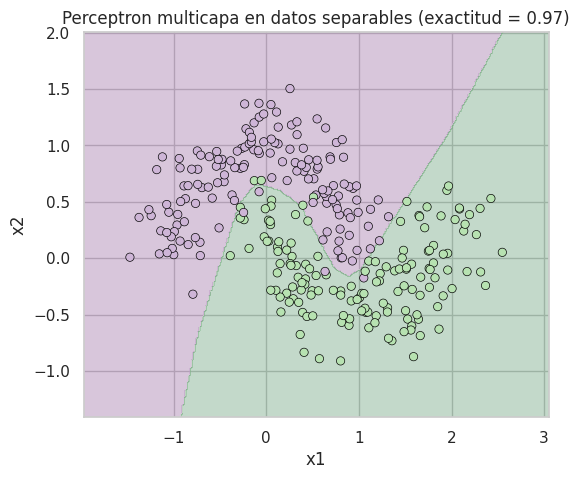

In [20]:
# 3. Perceptron multicapa
# Perceptrón multicapa. Entrenen un MLPClassifier (prueben con distinto número de neuronas en la capa oculta), calculen la exactitud y grafiquen la frontera.

mlp = MLPClassifier(
    hidden_layer_sizes=(16, 16), activation="relu", solver="adam",
    max_iter=2000, random_state=RANDOM_STATE,
)
mlp.fit(X, y)

acc_mlp = accuracy_score(y, mlp.predict(X))

graficar_frontera(mlp, X, y, f"Perceptron multicapa en datos separables (exactitud = {acc_mlp:.2f})")
plt.show()

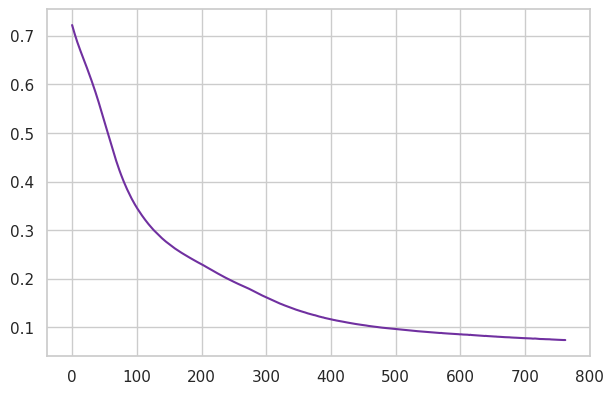

In [21]:
# 4. Curva de costo
# Curva de costo. Grafiquen loss_curve_ del MLP entrenado.

plt.figure(figsize=(7, 4.5))
plt.plot(mlp.loss_curve_, color="#7030A0")

In [24]:
# 5. Conclusion
# ¿Cuál modelo funciona mejor con estos datos? ¿Por qué el perceptrón simple no puede resolverlo?

# Funciona mejor el modelo de capas ya que tiene una precision del 0,97 que es superior al de
# Perceptron simple.
# El modelo de Perceptron simple no puede resolverlo ya que no es capaz de separar los puntos
# en una unica recta.